# 실습 문제 · 결제 수단 정산 시스템 리팩터링
### 다형성 — 리스트 하나, for 문 하나  ·  학생용

## 이야기

> 캠퍼스몰 **정산팀**의 지수 매니저가 민준에게 메신저를 보냅니다.
>
> *"매일 밤 결제 수단별 PG 수수료를 빼고 정산 금액을 뽑는 스크립트가 있는데요,
> 다음 달부터 **포인트 결제**가 추가돼요. 수수료는 0원이고 승인은 즉시예요. 반영 부탁드려요!"*
>
> 스크립트를 열어 보니, STEP 1에서 봤던 그 `if / elif` 구조가 또 있습니다.

### 결제 수단 규칙

| 결제 수단 | 클래스 이름 | 수수료 `fee()` | 승인 메시지 `approve_message()` |
|---|---|---|---|
| 신용카드 | `CardPayment` | 결제 금액의 2.5% (`amount * 25 // 1000`) | `"[카드] 카드사 승인 완료"` |
| 간편결제 | `EasyPayment` | 결제 금액의 1.8% (`amount * 18 // 1000`) | `"[간편결제] 앱 푸시 승인 완료"` |
| 계좌이체 | `BankTransfer` | 건당 500원 | `"[계좌이체] 입금 확인 대기"` |
| 포인트 *(신규)* | `PointPayment` | 0원 | `"[포인트] 즉시 차감 완료"` |

**정산 금액** = 결제 금액 − 수수료

## 지금의 코드 (레거시)

In [ ]:
def calc_fee(method, amount):
    if method == "카드":
        return amount * 25 // 1000
    elif method == "간편결제":
        return amount * 18 // 1000
    elif method == "계좌이체":
        return 500
    else:
        raise ValueError(f"알 수 없는 결제 수단: {method}")


def approve_message(method):
    if method == "카드":
        return "[카드] 카드사 승인 완료"
    elif method == "간편결제":
        return "[간편결제] 앱 푸시 승인 완료"
    elif method == "계좌이체":
        return "[계좌이체] 입금 확인 대기"
    else:
        raise ValueError(f"알 수 없는 결제 수단: {method}")


payments = [("카드", 100_000), ("간편결제", 50_000), ("계좌이체", 200_000)]

total_fee = 0
for method, amount in payments:
    fee = calc_fee(method, amount)
    total_fee += fee
    print(f"{approve_message(method):22} 결제 {amount:>8,}원  수수료 {fee:>5,}원")
print(f"총 수수료: {total_fee:,}원")

## 목표 구조

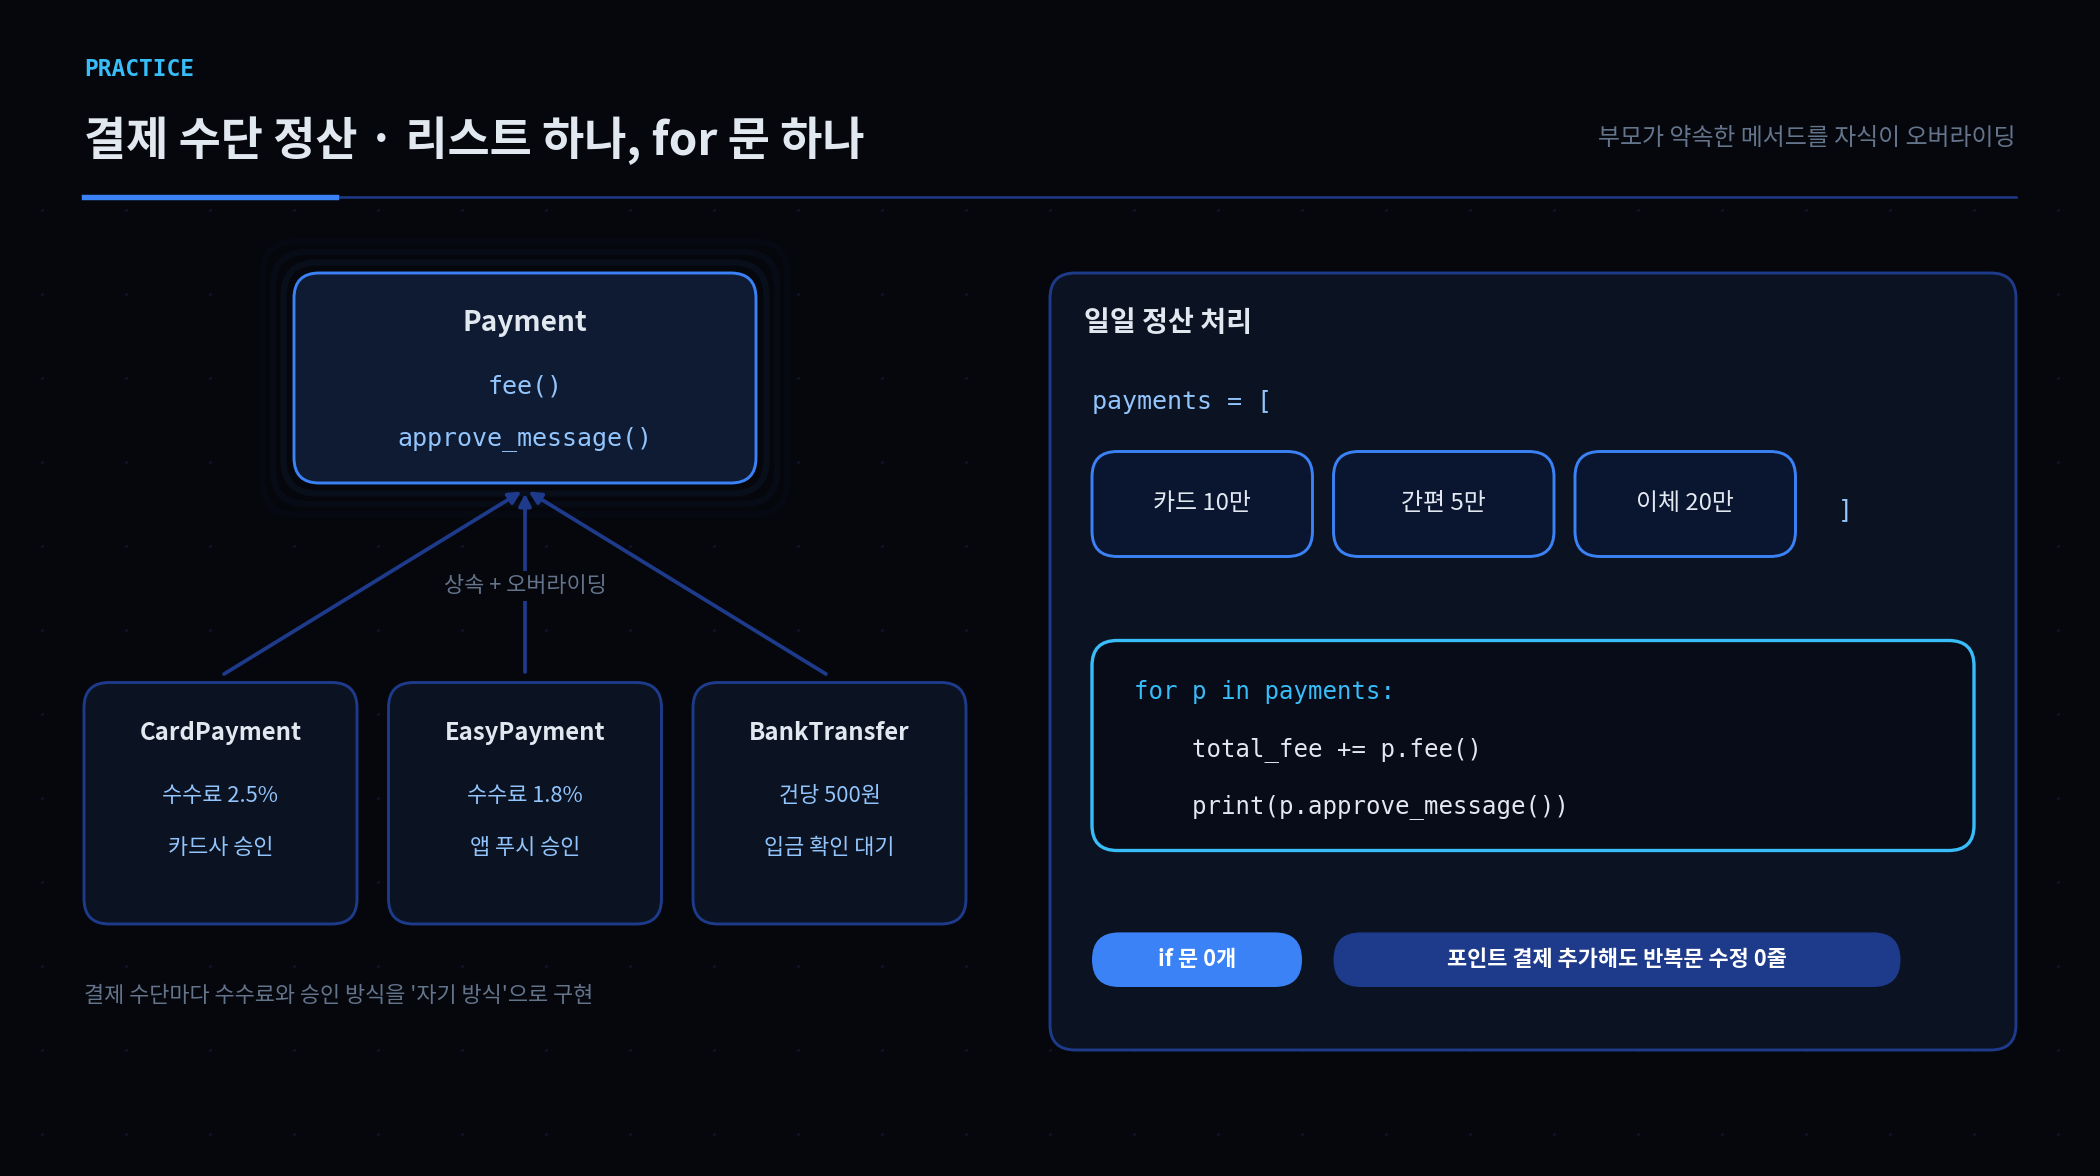

- 부모 `Payment` 가 **약속**을 정합니다: 모든 결제 수단은 `fee()` 와 `approve_message()` 를 가진다.
- 자식 클래스가 각자 **자기 방식으로 오버라이딩**합니다.
- 정산 루프는 결제 수단을 **묻지 않습니다.**

## 문제 1 · 부모 클래스 `Payment` 만들기

- `__init__(self, amount)` : 결제 금액 저장
- `fee(self)` : 자식이 반드시 구현해야 함 → `raise NotImplementedError`
- `approve_message(self)` : 자식이 반드시 구현해야 함 → `raise NotImplementedError`
- `settle_amount(self)` : **부모에서 직접 구현** — `self.amount - self.fee()` 반환

> `settle_amount()` 는 부모에 한 번만 쓰지만, 안에서 부르는 `self.fee()` 는 자식마다 다르게 동작합니다.

In [1]:
class Payment:
    def __init__(self, amount):
        self.amount = amount

    def fee(self):
        raise NotImplementedError(f"{type(self).__name__}은 fee() 기능을 구현해야 한다.")

    def approve_message(self):
        raise NotImplementedError(f"{type(self).__name__}은 approve_message() 기능을 구현해야 한다.") 

    def settle_amount(self): 
        return self.amount - self.fee()    

## 문제 2 · 자식 클래스 3개 만들기

위 규칙표대로 `CardPayment`, `EasyPayment`, `BankTransfer` 를 만들고 `fee()`, `approve_message()` 를 오버라이딩하세요.

In [5]:
class CardPayment(Payment):
    def fee(self):
        return self.amount*25 // 1000
    def approve_message(self):
        return "[카드] 카드사 승인 완료"
    
class EasyPayment(Payment):
    def fee(self):
            return self.amount*18 // 1000
    def approve_message(self):
            return "[간편결제] 앱 푸시 승인 완료"
    
class BankTransfer(Payment):
    def fee(self):
            return 500
    
    def approve_message(self):
            return "[계좌이체] 입금 확인 대기"

## 문제 3 · 리스트 하나, for 문 하나로 정산하기

`payments` 리스트를 순회하며 아래 세 값을 구하세요. **`if` 문과 `isinstance` 를 쓰지 마세요.**

- `total_fee` : 수수료 합계
- `total_settle` : 정산 금액 합계
- 각 결제마다 `approve_message()` 와 금액 출력

In [12]:
payments = [
    CardPayment(100_000),EasyPayment(50_000),BankTransfer(200_000)
]

total_fee = 0
total_settle = 0

for  p in  payments:
    total_fee += p.fee()
    total_settle += p.settle_amount()
    print(f"{p.approve_message():22} 결제 {p.amount:>8,}원 수수료 {p.fee():>5,}원")     


print(f"총 수수료: {total_fee:,}원 / 총 정산 금액: {total_settle:,}원")

[카드] 카드사 승인 완료         결제  100,000원 수수료 2,500원
[간편결제] 앱 푸시 승인 완료      결제   50,000원 수수료   900원
[계좌이체] 입금 확인 대기        결제  200,000원 수수료   500원
총 수수료: 3,900원 / 총 정산 금액: 346,100원


In [13]:
# 확인 셀 (문제 1~3)
assert CardPayment(100_000).fee() == 2_500
assert EasyPayment(50_000).fee() == 900
assert BankTransfer(200_000).fee() == 500
assert CardPayment(100_000).settle_amount() == 97_500
assert total_fee == 3_900
assert total_settle == 346_100
print("문제 1~3 통과!")

문제 1~3 통과!


## 문제 4 · 포인트 결제 추가 — 반복문 수정 0줄

지수 매니저의 요청을 반영하세요.
1. `PointPayment` 클래스를 만듭니다 (수수료 0원, 메시지 `"[포인트] 즉시 차감 완료"`).
2. `payments` 에 `PointPayment(30_000)` 을 **추가만** 합니다.
3. 아래 `settle()` 함수는 **한 글자도 고치지 않고** 그대로 실행합니다.

In [14]:
def settle(payments):
    """일일 정산 — 결제 수단을 묻지 않는다"""
    total_fee = sum(p.fee() for p in payments)
    total_settle = sum(p.settle_amount() for p in payments)
    print(f"{p.approve_message():22} 결제 {p.amount:>8,}원 수수료 {p.fee():>5,}원") 
    print(f"총 수수료: {total_fee:,}원 / 총 정산 금액: {total_settle:,}원")
    return total_fee, total_settle

In [15]:
class PointPayment(Payment):
    def fee(self):
        return 0 
    
    def approve_message(self):
        return "[포인트] 즉시 차감 완료"
    


# TODO: payments 에 PointPayment(30_000) 추가
payments.append(PointPayment(30_000))
result = settle(payments)

[계좌이체] 입금 확인 대기        결제  200,000원 수수료   500원
총 수수료: 3,900원 / 총 정산 금액: 376,100원


In [16]:
# 확인 셀 (문제 4)
assert PointPayment(30_000).fee() == 0
assert PointPayment(30_000).settle_amount() == 30_000
assert result == (3_900, 376_100)
print("문제 4 통과! 수정한 곳: 클래스 1개 추가 + 리스트 1줄 추가")

문제 4 통과! 수정한 곳: 클래스 1개 추가 + 리스트 1줄 추가


## 도전 문제 · 구현을 깜빡하면?

신입 개발자가 아래처럼 `fee()` 를 빼먹은 `GiftCardPayment` 를 만들었습니다.

1. 실행해서 **언제** 오류가 나는지 확인하세요.
2. `Payment` 를 `abc.ABC` + `@abstractmethod` 버전(`PaymentABC`)으로 바꾸면 오류 시점이 어떻게 달라지는지 확인하세요.

In [17]:
class GiftCardPayment(Payment):
    def approve_message(self):
        return "[상품권] 잔액 차감 완료"
    

g = GiftCardPayment(10_000)          # 1) 객체 생성은?
try:
    g.settle_amount()                # 2) 정산 시점은?
except NotImplementedError as e:
    print("NotImplementedError:", e)

NotImplementedError: GiftCardPayment은 fee() 기능을 구현해야 한다.


In [19]:
from abc import ABC, abstractmethod


class PaymentABC(ABC):
    def __init__(self, amount):self.amount = amount
    # TODO: __init__, 추상 메서드 fee / approve_message, settle_amount
    
    @abstractmethod
    def fee(self): ...

    @abstractmethod
    def approve_message(self): ...     

    def settle_amount(self):
        return self.amount - self.fee()


class GiftCardPaymentABC(PaymentABC):
    
    def fee(self):
        return 0

    def approve_message(self):
        return "[상품권] 잔액 차감 완료"


try:
    GiftCardPaymentABC(10_000)
    print("객체가 만들어졌습니다 — 추상 메서드를 확인하세요")
except TypeError as e:
    print("TypeError:", e)

객체가 만들어졌습니다 — 추상 메서드를 확인하세요
